In [ ]:
import cv2
import numpy as np
from skimage import io
from skimage.color import rgb2gray
from skimage.filters import threshold_otsu, median
from skimage.morphology import disk, opening, closing
from skimage.segmentation import watershed, slic, quickshift, clear_border
from skimage.feature import peak_local_max
from sklearn.cluster import KMeans
from sklearn.metrics import jaccard_score
from skimage.io import imread, imshow

# ISIC challenges 


**Cilj**: Segmentirati i identifikovati potencijalne kožne lezije na dermoskopskim slikama. Ovo može biti prvi korak u automatizovanim alatima za otkrivanje raka kože.

**Skup podataka**: ISIC (Međunarodna saradnja za slikanje kože) arhiva sadrži dermoskopske slike koje mogu biti korišćene za ovu svrhu. Iako je ceo skup podataka opsežan, podskup može biti korišćen za ovu demonstraciju. https://challenge.isic-archive.com/data/

**Procedura i metrika evaluacije**: Poređenje segmentiranog rezultata sa _Ground truth_ (ručno dodeljenim labelama na nivou piksela). Koristićemo _Jaccard_-ov koeficijent sličnosti (presek preko unije - _IoU_) kao metriku evaluacije.

## Dataset loading

Min value: 0
Max value: 255
Min value: 0.0
Max value: 1.0


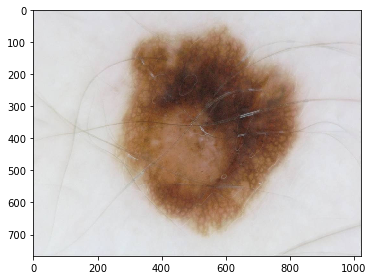

In [2]:
image_url = "./ISBI2016_ISIC_Part1_Test_Data/ISIC_0000003.jpg"
mask_url = "./ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0000003_Segmentation.png"

original = io.imread(image_url)
ground_truth = io.imread(mask_url)

print("Min value:", np.min(ground_truth))
print("Max value:", np.max(ground_truth))
# ground_truth je binarna slika sa vrednostima 0 (pozadina) i 255 (mladež). Mapiraćemo je na vrednosti 0 i 1
ground_truth = ground_truth / 255
print("Min value:", np.min(ground_truth))
print("Max value:", np.max(ground_truth))

image = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

imshow(original)

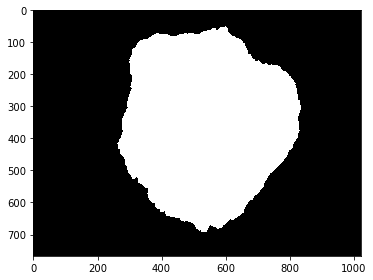

In [3]:
imshow(ground_truth)

## Preprocessing

Min value: 0.08355058823529411
Max value: 1.0


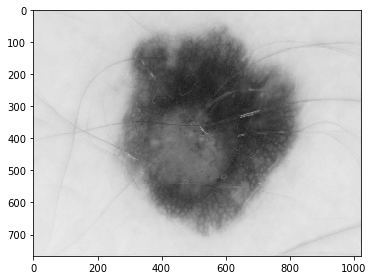

In [4]:
gray = rgb2gray(image)
imshow(gray)

print("Min value:", np.min(gray))
print("Max value:", np.max(gray))

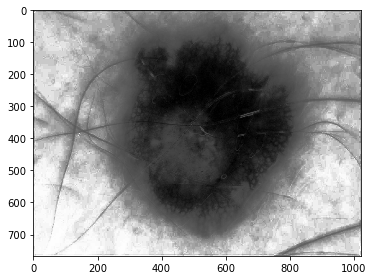

In [5]:
# Histogram equalization
equalized = cv2.equalizeHist((gray * 255).astype(np.uint8))
imshow(equalized)

Pojačanje kontrasta nije pomoglo - iako je kontrast uvećan, uvećan je i šum.

# Segmentation
## Otsu

0.5936835615808824


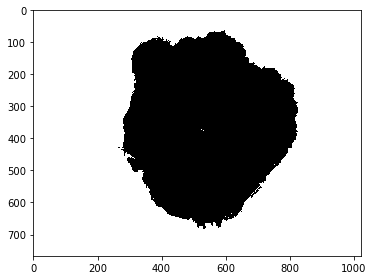

In [6]:
print(threshold_otsu(gray))
binary_global = gray > threshold_otsu(gray)
imshow(binary_global)

Segmentacija nije loša, međutim, prisutan je šum. Probaćemo prvo izglađivanje korišćenjem _local_averaging_ pristupa:

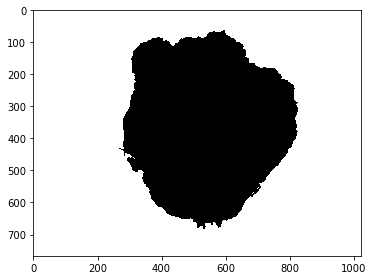

In [7]:
smoothed = cv2.blur(binary_global.astype(np.uint8), (5, 5))
binary_smoothed = smoothed > threshold_otsu(smoothed)
imshow(binary_smoothed)

Dodatno, izgladićemo ivice primenom morfoloških operacija otvaranja i zatvaranja:

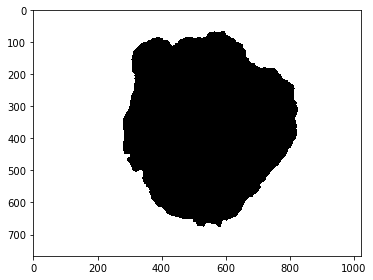

In [8]:
# Morphological operations
structure_element = disk(5)
morphed = opening(binary_smoothed, structure_element)
morphed = closing(morphed, structure_element)

otsu_mask = morphed
imshow(otsu_mask)

# Dobijena maska je invertovana u odnosu na ground_truth, pa mapiramo 0 na 1 i obrnuto:
otsu_mask = (otsu_mask == 0).astype(int)

## K-means clustering based on color

(767, 1022, 3)
(783874, 3)
Min value: 0
Max value: 1


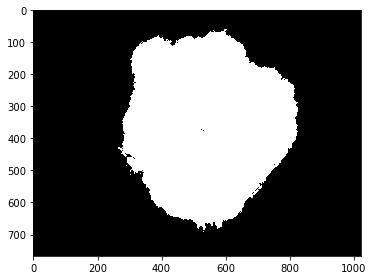

In [9]:
print(image.shape) # slika je dimenzije width x height x 3 (kanali za RGB)
image_flat = image.reshape(-1, 3) # pretvaramo sliku u vektor (height*width, 3) - svaki red je RGB pojedinačnog piksela, tj. slika je "flattened" u listu vrednosti piksela
print(image_flat.shape)

kmeans = KMeans(n_clusters=2, random_state=0).fit(image_flat) # svaki piksel u image_flat ima dodeljen klaster (0 ili 1) u kmeans.labels_
segmented_kmeans = kmeans.labels_.reshape(image.shape[0], image.shape[1]) # kmeans.labels_ je 1D niz, reshape-ujemo ga u originalne dimenzije slike

#imshow(segmented_kmeans)
segmented_kmeans.shape
print("Min value:", np.min(segmented_kmeans))
print("Max value:", np.max(segmented_kmeans))

segmented_kmeans = 1 - segmented_kmeans
imshow(segmented_kmeans.astype(float))

Možemo srediti rezultat morfološkim operacijama:

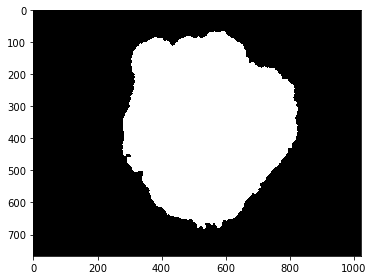

In [10]:
# Morphological operations
structure_element = disk(3)
segmented_kmeans = opening(segmented_kmeans, structure_element)
segmented_kmeans = closing(segmented_kmeans, structure_element)

imshow(segmented_kmeans.astype(float))

## Superpixels

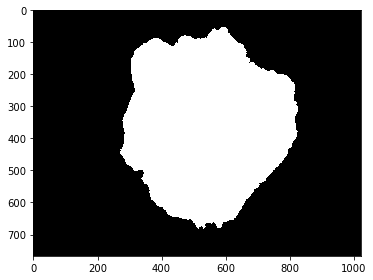

In [11]:
# Superpixels using SLIC
#superpixels = slic(image, n_segments=100, compactness=10)
#imshow(superpixels)

# image - grayscale slika čije superpiksele želimo da spojimo
# labels - svaki superpiksel ima svoju jedinstvenu labelu
# željeni broj segmenata nakon spajanja
def merge_superpixels(image, labels, n_clusters=2):
    """Merge superpixels based on K-means clustering of their average intensities."""
    unique_labels = np.unique(labels) # dobijamo sve jedinstvene labele
    avg_intensities = [image[labels == i].mean() for i in unique_labels] # računamo prosečan intenzitet svakog superpiksela
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(np.array(avg_intensities).reshape(-1, 1)) # klasteruj superpiksele u 2 klastera (koristeći prosečnu vrednost superpiksela)
    
    # ažuriraj labele superpiksela prema klasterima formiranim od strane KMeans
    merged_image = np.zeros_like(image)
    for label, cluster_label in zip(unique_labels, kmeans.labels_):
        merged_image[labels == label] = cluster_label

    return merged_image

# Inicijalizovaćemo na mnogo superpiksela
labels = slic(image, n_segments=500, compactness=10, sigma=1)
superpixels = merge_superpixels(gray, labels, 2)
imshow(superpixels)

In [22]:
# Region Growing using quickshift segmentation
#regions = quickshift(image, ratio=0.9, max_dist=5, convert2lab=True)
# Region-growing (Quickshift): The ratio and max_dist can affect how regions are grown.

## Watershead

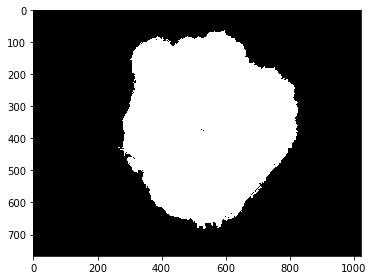

In [13]:
# Otsu's thresholding
_, otsu_thresh = cv2.threshold((gray * 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
otsu_thresh = 255 - otsu_thresh
imshow(otsu_thresh)

Radimo dilaciju - sve što ostanu crni pikseli nakon toga su sigurno pozadina

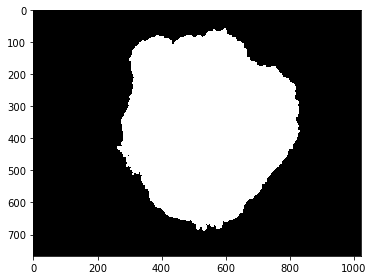

In [14]:
kernel = np.ones((3,3), np.uint8)
sure_bg = cv2.dilate(otsu_thresh, kernel, iterations=3)
imshow(sure_bg)

Pronalazimo piksele koji su sigurno objekat od interesa: dist_transform računa rastojanje svakog piksela do najbližeg 0 piksela. Pikseli najdalje od pozadine su sigurno pikseli od interesa

C:\Users\slivk\AppData\Roaming\Python\Python38\site-packages\skimage\io\_plugins\matplotlib_plugin.py:149: UserWarning: Float image out of standard range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


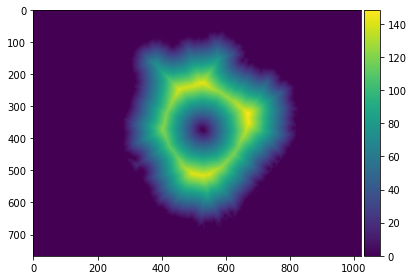

In [15]:
dist_transform = cv2.distanceTransform(otsu_thresh, cv2.DIST_L2, 5)
imshow(dist_transform)

_, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

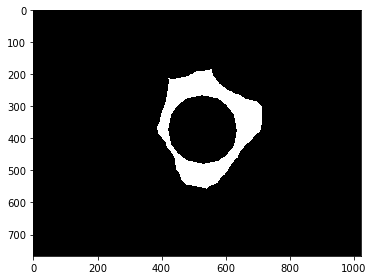

In [16]:
sure_fg = np.uint8(sure_fg)
imshow(sure_fg )

Između su pikseli oko kojih smo nesigurni (da li su foreground ili background) - tu negde se nalaze watershed linije

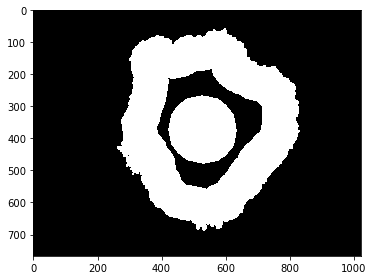

In [17]:
# Finding unknown region by subtracting sure foreground from the sure background
unknown = cv2.subtract(sure_bg, sure_fg)
imshow(unknown)

C:\Users\slivk\AppData\Roaming\Python\Python38\site-packages\skimage\io\_plugins\matplotlib_plugin.py:149: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


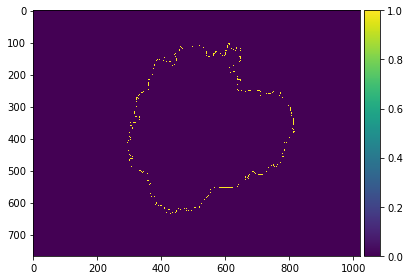

In [18]:
# Marker labelling
# This labels the regions inside the images, so that distinct regions (connected components) have unique labels. 
# The markers will be updated by the watershed algorithm to have -1 at boundary regions.
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Applying the watershed
cv2.watershed(image, markers)

# Creating the binary mask
watershed_mask = np.where((markers == -1), 1, 0).astype(np.uint8)

imshow(watershed_mask)

[-1  1  2]


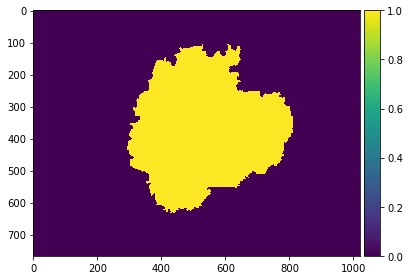

In [19]:
# After the watershed
cv2.watershed(image, markers)

# Let's find out the unique markers
unique_markers = np.unique(markers)

# If the watershed worked perfectly, you should have more than two unique markers.
# The -1 marker denotes boundaries. The others denote segmented regions.
watershed_mask = np.zeros_like(markers)

# Assuming two major regions segmented, let's find their average intensities
if len(unique_markers) > 2:
    print(unique_markers)
    watershed_mask[markers == 2] = 1
else:
    print("Watershed didn't segment the image as expected.")
    
imshow(watershed_mask)

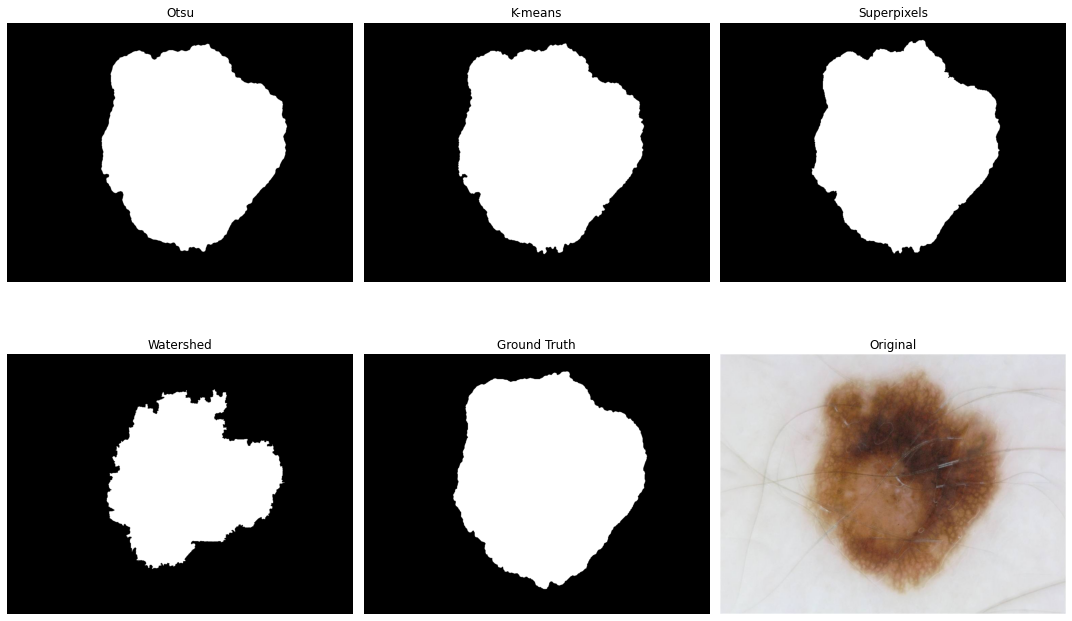

In [20]:
# Visualization
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
ax_idx = 0

for segmented, name in zip([otsu_mask, segmented_kmeans, superpixels, watershed_mask, ground_truth, original],
                           ["Otsu", "K-means", "Superpixels", "Watershed", "Ground Truth", "Original"]):
    axes[ax_idx].imshow(segmented, cmap="gray")
    axes[ax_idx].set_title(name)
    axes[ax_idx].axis('off')
    ax_idx += 1

plt.tight_layout()
plt.show()

## Evaluation

_Jaccard score_ uzima vrednosti između 0 (nema preklapanja maske i rezultata) i 1 (perfektno preklapanje maske i rezultata). 

In [21]:
# 3.3. Evaluation
score_otsu = jaccard_score(ground_truth.flatten(), otsu_mask.flatten(), average='macro')
score_kmeans = jaccard_score(ground_truth.flatten(), segmented_kmeans.flatten(), average='macro')
score_superpixels = jaccard_score(ground_truth.flatten(), superpixels.flatten(), average='macro')
#score_regions = jaccard_score(ground_truth.flatten(), regions.flatten(), average='macro')
score_watershed = jaccard_score(ground_truth.flatten(), watershed_mask.flatten(), average='macro')

print(f"Jaccard Score for Otsu: {score_otsu}")
print(f"Jaccard Score for K-means: {score_kmeans}")
print(f"Jaccard Score for Superpixels: {score_superpixels}")
#print(f"Jaccard Score for Region Growing: {score_regions}")
print(f"Jaccard Score for Watershed: {score_watershed}")

Jaccard Score for Otsu: 0.9493655555294624
Jaccard Score for K-means: 0.9518917416466655
Jaccard Score for Superpixels: 0.9540474467065838
Jaccard Score for Watershed: 0.7678950526252097


# Diskusija

Uticaj različitih parametara:
- Histogram equalization: poboljšava kontrast, što može da utiče na kasnije zadatke.
- Uklanjanje šuma: veličina kernela utiče koliko je slika izglađena. Veliki kernel može (nepoželjno) da ukloni detalje lezije.
- Morfološke operacije: veličina strukturnog elementa može da utiče na ishod. Prevelika vrednost će da erodira/raširi važne delove; Premala veličina imati željeni efekat uklanjanja šuma. Oblik strukturnog elementa (disk/kvadrat) treba prilagoditi obliku elemenata na slici.
- K-means: Broj klastera utiče na rezultujuću segmentaciju. Mi smo koristili 2 podrazumevajući da imamo leziju i kožu (pozadinu), ali se ovo može podesiti.
- Superpixels (SLIC): Broj segmenata i kompaktnost značajno utiču na granularnost rezultata.
- Watershed: The footprint in peak_local_max affects local maxima detection.

Rezultati:
- Različite metode segmentacije daju različite rezultate, gde su neke tehnike primerenije za određene tipove slika ili lezija.
- Jaccard score daje kvantitativnu metriku za poređenje metoda, ali je i vizuelna inspekcija krucijalna.